<a href="https://colab.research.google.com/github/Shashi-kumar-g/machine-learning-26/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
   Study_Hours  Result
0            1       0
1            2       0
2            3       0
3            4       0
4            5       0
5            6       1
6            7       1
7            8       1
8            9       1
9           10       1

Actual Values: [0, 0, 1]
Predicted Values: [np.int64(0), np.int64(0), np.int64(1)]

Accuracy: 100.0 %

Confusion Matrix:
[[2 0]
 [0 1]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3


Prediction: Pass
Pass Probability: 0.8613684581837455


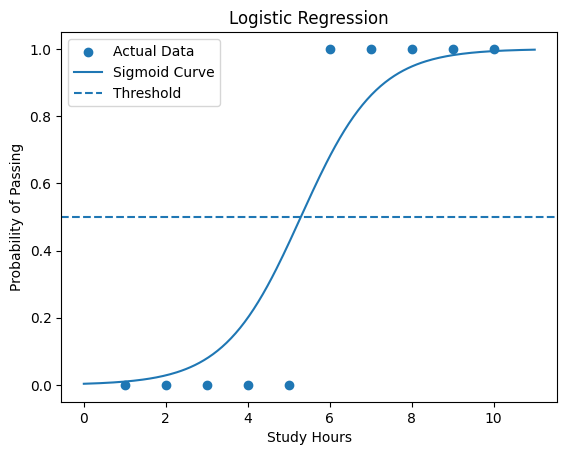

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Step 1: Create Dataset
data = {
    'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Result':      [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Step 2: Separate Input and Output
X = df[['Study_Hours']]
Y = df['Result']

# Step 3: Split Dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42, stratify=Y
)

# Step 4: Create Model
model = LogisticRegression()

# Step 5: Train Model
model.fit(X_train, Y_train)

# Step 6: Prediction
Y_pred = model.predict(X_test)

print("\nActual Values:", list(Y_test))
print("Predicted Values:", list(Y_pred))

# Step 7: Accuracy
accuracy = accuracy_score(Y_test, Y_pred)
print("\nAccuracy:", accuracy * 100, "%")

# Step 8: Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

# Step 9: Classification Report
print("\nClassification Report:")
print(classification_report(Y_test, Y_pred, zero_division=0))

# Step 10: Predict New Student
new_student = pd.DataFrame({'Study_Hours': [7]})

prediction = model.predict(new_student)
probability = model.predict_proba(new_student)

print("\nPrediction:", "Pass" if prediction[0] == 1 else "Fail")
print("Pass Probability:", probability[0][1])

# Step 11: Plot Sigmoid Curve
hours = pd.DataFrame({
    'Study_Hours': np.linspace(0, 11, 200)
})

probabilities = model.predict_proba(hours)[:, 1]

plt.scatter(X, Y, label="Actual Data")
plt.plot(hours, probabilities, label="Sigmoid Curve")
plt.axhline(0.5, linestyle='--', label="Threshold")
plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression")
plt.legend()
plt.show()
